# DSA 1101 — Retail Sales Analytics

**Group members:**
1. Maxwell Mbondo - 24/06667
2. Mark Kitema - 24/06543
3. Hamdi Mohamed - 24/08115
4. Feisal Noor - 24/07112

**Course:** DSA 1101 ? Principles of Data Science  
**Dataset:** `DSA1101_Practical_Assignments_Datasets.xlsx`, worksheet `A2_Retail_Sales`

## Purpose and provenance
This notebook audits and analyzes simulated retail transactions, summarizes revenue in Kenyan shillings (KES), visualizes performance and compares introductory regression models. These records are synthetic teaching data, not actual business observations. The analysis is exploratory and the model is not a production forecasting system.

## Prediction question
Can transaction revenue be reconstructed from units, price, discount, category, region, payment/channel and date features? Since net revenue is mathematically determined by units × price × (1 − discount), this setup intentionally exposes a target-construction shortcut. Excellent model scores would **not** demonstrate future forecasting skill. For a genuine pre-transaction forecast, define a target and predictors available before the transaction.

In [1]:
from pathlib import Path
import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
DATA_FILE = Path("DSA1101_Practical_Assignments_Datasets.xlsx")
OUT = Path("outputs")
FIG = OUT / "figures"
OUT.mkdir(exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
print({
    "Python": platform.python_version(),
    "pandas": pd.__version__,
    "NumPy": np.__version__,
    "Matplotlib": plt.matplotlib.__version__,
    "Seaborn": sns.__version__,
    "scikit-learn": sklearn.__version__,
})
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Place {DATA_FILE.name} beside this notebook before running."
    )
raw = pd.read_excel(DATA_FILE, sheet_name="A2_Retail_Sales")
print("Raw shape:", raw.shape)
display(raw.head(), raw.dtypes.rename("dtype").to_frame(),
        raw.describe(include="all").T)

{'Python': '3.13.14', 'pandas': '3.1.1', 'NumPy': '2.5.4', 'Matplotlib': '3.11.2', 'Seaborn': '0.13.2', 'scikit-learn': '1.9.1'}


Raw shape: (262, 10)


,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES
0,TX0001,2025-03-20,Coast,Food,2,409.65,0.15,Mobile Money,Store,696.40
1,TX0002,2025-06-29,NaN,Food,8,1047.14,0.00,Mobile Money,Store,8377.12
2,TX0003,2025-06-02,Coast,Clothing,1,1374.69,0.00,Card,Store,1374.69
3,TX0004,2025-04-17,Coast,Clothing,3,3861.90,0.00,Cash,Store,11585.70
4,TX0005,2025-01-05,Western,Food,1,701.62,0.15,Mobile Money,Online,596.38


,dtype
Transaction_ID,str
Date,datetime64[us]
Region,str
Product_Category,str
Units_Sold,int64
Unit_Price_KES,float64
Discount_Rate,float64
Payment_Method,str
Sales_Channel,str
Revenue_KES,float64


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Transaction_ID,262,260,TX0021,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,262,NaN,NaN,NaN,2025-04-03 10:15:34.351145,2025-01-01 00:00:00,2025-02-13 00:00:00,2025-04-07 12:00:00,2025-05-25 18:00:00,2025-06-29 00:00:00,NaN
Region,257,5,Western,65,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Category,262,5,Clothing,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Units_Sold,262.0,NaN,NaN,NaN,4.973282,1.0,3.0,5.0,7.0,100.0,6.341741
Unit_Price_KES,257.0,NaN,NaN,NaN,7143.780156,81.58,1001.51,2483.14,5950.27,250000.0,17983.687224
Discount_Rate,262.0,NaN,NaN,NaN,0.074809,0.0,0.0,0.1,0.1,0.2,0.06917
Payment_Method,257,4,Mobile Money,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales_Channel,262,2,Store,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Revenue_KES,262.0,NaN,NaN,NaN,25089.461908,70.54,2934.3175,8920.24,22679.1625,313895.68,45980.561641


## Data-quality audit and cleaning plan
- Parse dates and numeric fields; retain the supplied revenue for an independent consistency check.
- The two repeated transaction IDs are exact duplicate rows. Keep one copy per transaction ID.
- Keep all valid, unusual quantities and prices (including the extreme price); flag them rather than deleting them.
- Retain rows with unknown region/payment method using an explicit `Unknown` category.
- Impute missing unit prices with the median for that product category and log every imputation. This retains transactions without pretending the missing price was observed.
- Recalculate net revenue from the assignment’s formula and use it as the analysis target. Flag differences from supplied revenue above one cent; do not silently trust either field.

In [2]:
retail = raw.copy()
numeric_cols = ["Units_Sold", "Unit_Price_KES", "Discount_Rate", "Revenue_KES"]
retail["Date"] = pd.to_datetime(retail["Date"], errors="coerce")
for col in numeric_cols:
    retail[col] = pd.to_numeric(retail[col], errors="coerce")

audit = []
quality_events = []
audit.append({
    "issue": "Exact duplicate rows",
    "count": int(retail.duplicated().sum()),
    "decision": "Drop repeated transaction rows; retain first occurrence.",
})
duplicate_rows = retail.loc[
    retail.duplicated(subset="Transaction_ID", keep="first")
]
for _, row in duplicate_rows.iterrows():
    quality_events.append({
        "record_id": row["Transaction_ID"],
        "issue": "Duplicate transaction identifier",
        "original_value": "Repeated exact row",
        "action": "Removed repeated row; retained first occurrence.",
    })
audit.append({
    "issue": "Duplicate transaction identifiers",
    "count": int(retail["Transaction_ID"].duplicated().sum()),
    "decision": "Keep first row per ID after confirming duplicates are exact.",
})
retail = retail.drop_duplicates(subset="Transaction_ID", keep="first").copy()

for col in ["Region", "Payment_Method"]:
    missing = int(retail[col].isna().sum())
    for record_id in retail.loc[retail[col].isna(), "Transaction_ID"]:
        quality_events.append({
            "record_id": record_id,
            "issue": f"Missing {col}",
            "original_value": "",
            "action": "Set to explicit Unknown category.",
        })
    retail[col] = retail[col].fillna("Unknown")
    audit.append({
        "issue": f"Missing {col}", "count": missing,
        "decision": "Preserve row and label category Unknown.",
    })

invalid = (
    retail["Date"].isna()
    | retail["Units_Sold"].isna()
    | retail["Units_Sold"].le(0)
    | retail["Unit_Price_KES"].le(0)
    | retail["Discount_Rate"].lt(0)
    | retail["Discount_Rate"].ge(1)
)
invalid_count = int(invalid.sum())
for _, row in retail.loc[invalid].iterrows():
    quality_events.append({
        "record_id": row["Transaction_ID"],
        "issue": "Invalid essential value",
        "original_value": str(row[numeric_cols + ["Date"]].to_dict()),
        "action": "Excluded from cleaned analysis data.",
    })
audit.append({
    "issue": "Invalid essential values",
    "count": invalid_count,
    "decision": "Exclude rows only if an essential field is invalid; inspect before removal.",
})
if invalid_count:
    display(retail.loc[invalid])
    retail = retail.loc[~invalid].copy()

missing_price = retail["Unit_Price_KES"].isna()
price_medians = retail.groupby("Product_Category")["Unit_Price_KES"].transform("median")
for idx in retail.index[missing_price]:
    quality_events.append({
        "record_id": retail.at[idx, "Transaction_ID"],
        "issue": "Missing Unit_Price_KES",
        "original_value": "",
        "action": (
            "Imputed with product-category median: "
            f"{price_medians.at[idx]:.2f} KES."
        ),
    })
retail.loc[missing_price, "Unit_Price_KES"] = price_medians[missing_price]
audit.append({
    "issue": "Missing unit price",
    "count": int(missing_price.sum()),
    "decision": "Impute with within-category median; rows are flagged in the quality log.",
})
retail["Revenue_Calculated_KES"] = (
    retail["Units_Sold"] * retail["Unit_Price_KES"] * (1 - retail["Discount_Rate"])
)
retail["Revenue_Difference_KES"] = (
    retail["Revenue_Calculated_KES"] - retail["Revenue_KES"]
)
mismatch = retail["Revenue_Difference_KES"].abs().gt(0.01)
for _, row in retail.loc[mismatch].iterrows():
    quality_events.append({
        "record_id": row["Transaction_ID"],
        "issue": "Revenue formula mismatch",
        "original_value": (
            f"supplied={row['Revenue_KES']:.2f}; "
            f"calculated={row['Revenue_Calculated_KES']:.2f}; "
            f"difference={row['Revenue_Difference_KES']:.2f} KES"
        ),
        "action": "Used formula-derived net revenue; retained supplied value in audit columns.",
    })
audit.append({
    "issue": "Supplied revenue differs from calculated revenue by > KES 0.01",
    "count": int(mismatch.sum()),
    "decision": "Use formula-derived net revenue; retain supplied value and difference for audit.",
})
retail["Revenue_KES"] = retail["Revenue_Calculated_KES"]

extreme_price = retail["Unit_Price_KES"].gt(
    retail["Unit_Price_KES"].quantile(0.99)
)
extreme_units = retail["Units_Sold"].gt(retail["Units_Sold"].quantile(0.99))
retail["Extreme_Value_Flag"] = extreme_price | extreme_units
for _, row in retail.loc[retail["Extreme_Value_Flag"]].iterrows():
    quality_events.append({
        "record_id": row["Transaction_ID"],
        "issue": "High price/quantity flag",
        "original_value": (
            f"unit_price={row['Unit_Price_KES']:.2f} KES; "
            f"units={row['Units_Sold']}"
        ),
        "action": "Retained and flagged; verify against source receipt.",
    })
audit.append({
    "issue": "High price/quantity flag (above 99th percentile)",
    "count": int(retail["Extreme_Value_Flag"].sum()),
    "decision": "Retain and flag; no transaction is removed solely for being extreme.",
})
retail["Month"] = retail["Date"].dt.month
retail["Day_Of_Week"] = retail["Date"].dt.day_of_week
retail["Is_Weekend"] = retail["Day_Of_Week"].ge(5).astype(int)
retail["Discount_Amount_KES"] = (
    retail["Units_Sold"] * retail["Unit_Price_KES"] * retail["Discount_Rate"]
)
retail["Gross_Value_KES"] = retail["Units_Sold"] * retail["Unit_Price_KES"]

audit_df = pd.DataFrame(audit)
quality_log = pd.DataFrame(quality_events)
display(audit_df)
retail.to_csv(OUT / "A2_Retail_cleaned.csv", index=False)
audit_df.to_csv(OUT / "A2_Retail_quality_summary.csv", index=False)
quality_log.to_csv(OUT / "A2_Retail_quality_log.csv", index=False)
display(quality_log.head(10))
print("Clean data shape:", retail.shape)
print("Date window:", retail["Date"].min().date(), "to", retail["Date"].max().date())
print("Duplicate IDs remaining:", retail["Transaction_ID"].duplicated().sum())

,issue,count,decision
0,Exact duplicate rows,2,Drop repeated transaction rows; retain first o...
1,Duplicate transaction identifiers,2,Keep first row per ID after confirming duplica...
2,Missing Region,5,Preserve row and label category Unknown.
3,Missing Payment_Method,5,Preserve row and label category Unknown.
4,Invalid essential values,0,Exclude rows only if an essential field is inv...
5,Missing unit price,5,Impute with within-category median; rows are f...
6,Supplied revenue differs from calculated reven...,7,Use formula-derived net revenue; retain suppli...
7,High price/quantity flag (above 99th percentile),3,Retain and flag; no transaction is removed sol...


,record_id,issue,original_value,action
0,TX0021,Duplicate transaction identifier,Repeated exact row,Removed repeated row; retained first occurrence.
1,TX0091,Duplicate transaction identifier,Repeated exact row,Removed repeated row; retained first occurrence.
2,TX0002,Missing Region,,Set to explicit Unknown category.
3,TX0015,Missing Region,,Set to explicit Unknown category.
4,TX0213,Missing Region,,Set to explicit Unknown category.
5,TX0224,Missing Region,,Set to explicit Unknown category.
6,TX0226,Missing Region,,Set to explicit Unknown category.
7,TX0096,Missing Payment_Method,,Set to explicit Unknown category.
8,TX0123,Missing Payment_Method,,Set to explicit Unknown category.
9,TX0173,Missing Payment_Method,,Set to explicit Unknown category.


Clean data shape: (260, 18)
Date window: 2025-01-01 to 2025-06-29
Duplicate IDs remaining: 0


## Descriptive sales analysis
The following measures use formula-derived net transaction revenue. Means and medians are shown together because the distribution is right-skewed. Period comparisons cover only the dates present in this synthetic sample.

In [3]:
overall = pd.DataFrame([{
    "Transactions": len(retail),
    "Total revenue (KES)": retail["Revenue_KES"].sum(),
    "Total units sold": retail["Units_Sold"].sum(),
    "Average transaction revenue (KES)": retail["Revenue_KES"].mean(),
    "Median transaction revenue (KES)": retail["Revenue_KES"].median(),
    "Average discount rate": retail["Discount_Rate"].mean(),
}])
category = (
    retail.groupby("Product_Category", as_index=False)
    .agg(
        Transactions=("Transaction_ID", "nunique"),
        Revenue_KES=("Revenue_KES", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Average_Selling_Price_KES=("Unit_Price_KES", "mean"),
        Average_Discount=("Discount_Rate", "mean"),
    )
    .sort_values("Revenue_KES", ascending=False)
)
region_channel = retail.pivot_table(
    index="Region", columns="Sales_Channel", values="Revenue_KES",
    aggfunc="sum", fill_value=0, margins=True,
)
category_region_revenue = pd.pivot_table(
    retail, index="Product_Category", columns="Region",
    values="Revenue_KES", aggfunc="sum", fill_value=0,
)
category_region_count = pd.pivot_table(
    retail, index="Product_Category", columns="Region",
    values="Transaction_ID", aggfunc="nunique", fill_value=0,
)
monthly = (
    retail.assign(Period=retail["Date"].dt.to_period("M").astype(str))
    .groupby("Period", as_index=False)
    .agg(Revenue_KES=("Revenue_KES", "sum"),
         Transactions=("Transaction_ID", "nunique"))
)
channel = retail.groupby("Sales_Channel", as_index=False).agg(
    Transactions=("Transaction_ID", "nunique"),
    Revenue_KES=("Revenue_KES", "sum"),
    Average_Transaction_KES=("Revenue_KES", "mean"),
)
payment = retail.groupby("Payment_Method", as_index=False).agg(
    Transactions=("Transaction_ID", "nunique"),
    Revenue_KES=("Revenue_KES", "sum"),
    Average_Transaction_KES=("Revenue_KES", "mean"),
)
display(overall.T.rename(columns={0: "Value"}))
display(category, region_channel, category_region_revenue,
        category_region_count, monthly, channel, payment)
for name, table in {
    "A2_Retail_category_summary": category,
    "A2_Retail_region_channel_revenue": region_channel,
    "A2_Retail_category_region_revenue": category_region_revenue,
    "A2_Retail_category_region_counts": category_region_count,
    "A2_Retail_monthly_summary": monthly,
    "A2_Retail_channel_summary": channel,
    "A2_Retail_payment_summary": payment,
}.items():
    table.to_csv(OUT / f"{name}.csv")
print("Highest month:", monthly.loc[monthly["Revenue_KES"].idxmax()].to_dict())
print("Lowest month:", monthly.loc[monthly["Revenue_KES"].idxmin()].to_dict())
print("Revenue leader:", category.iloc[0]["Product_Category"])
print("Unit leader:", category.loc[category["Units_Sold"].idxmax(), "Product_Category"])

,Value
Transactions,2.600000e+02
Total revenue (KES),8.813869e+06
Total units sold,1.296000e+03
Average transaction revenue (KES),3.389950e+04
Median transaction revenue (KES),8.964200e+03
Average discount rate,7.480769e-02


,Product_Category,Transactions,Revenue_KES,Units_Sold,Average_Selling_Price_KES,Average_Discount
1,Electronics,40,5.336804e+06,195,29762.506500,0.077500
3,Home,46,2.149103e+06,294,6448.978478,0.072826
0,Clothing,69,9.222438e+05,302,3433.692464,0.085507
4,Personal Care,42,2.346962e+05,207,1240.026429,0.067857
2,Food,63,1.710218e+05,298,605.014365,0.067460


Sales_Channel,Online,Store,All
Region,,,
Central,5.442029e+05,8.792267e+05,1.423430e+06
Coast,1.884656e+06,1.564240e+06,3.448896e+06
Nairobi,4.658562e+05,4.607800e+05,9.266362e+05
Rift Valley,6.560133e+05,6.283314e+05,1.284345e+06
Unknown,6.133158e+04,1.744994e+04,7.878152e+04
Western,5.939568e+05,1.057824e+06,1.651781e+06
All,4.206017e+06,4.607852e+06,8.813869e+06


Region,Central,Coast,Nairobi,Rift Valley,Unknown,Western
Product_Category,,,,,,
Clothing,1.192328e+05,2.034168e+05,159713.192,131407.45200,0.0000,308473.5680
Electronics,1.063001e+06,1.876795e+06,570396.394,784615.56200,57555.8120,984440.3985
Food,3.695277e+04,4.710636e+04,22064.676,27479.28275,8377.1200,29041.6250
Home,1.566979e+05,1.281932e+06,138384.399,250639.37900,3775.7700,317673.5715
Personal Care,4.754454e+04,3.964692e+04,36077.491,90202.99950,9072.8175,12151.4540


Region,Central,Coast,Nairobi,Rift Valley,Unknown,Western
Product_Category,,,,,,
Clothing,8,17,12,12,0,20
Electronics,9,7,6,4,1,13
Food,13,16,9,11,1,13
Home,6,8,6,12,1,13
Personal Care,9,6,8,13,2,4


,Period,Revenue_KES,Transactions
0,2025-01,8.980234e+05,44
1,2025-02,2.511100e+06,45
2,2025-03,8.521306e+05,36
3,2025-04,1.068941e+06,43
4,2025-05,2.190702e+06,35
5,2025-06,1.292972e+06,57


,Sales_Channel,Transactions,Revenue_KES,Average_Transaction_KES
0,Online,100,4.206017e+06,42060.165615
1,Store,160,4.607852e+06,28799.077267


,Payment_Method,Transactions,Revenue_KES,Average_Transaction_KES
0,Bank Transfer,31,5.825049e+05,18790.481274
1,Card,54,3.956365e+06,73266.016315
2,Cash,50,7.083256e+05,14166.511960
3,Mobile Money,120,3.364915e+06,28040.962440
4,Unknown,5,2.017580e+05,40351.606600


Highest month: {'Period': '2025-02', 'Revenue_KES': 2511100.0865, 'Transactions': 45}
Lowest month: {'Period': '2025-03', 'Revenue_KES': 852130.577, 'Transactions': 36}
Revenue leader: Electronics
Unit leader: Clothing


## Visualizations
The plots are saved as PNG files under `outputs/figures/` for the report.

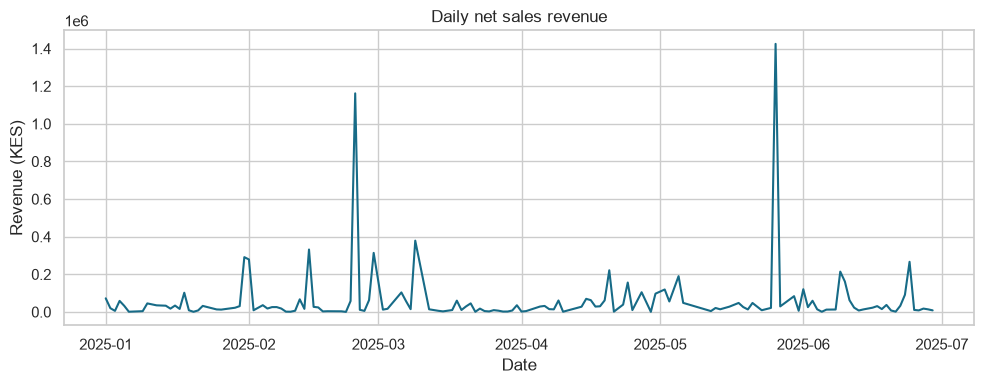

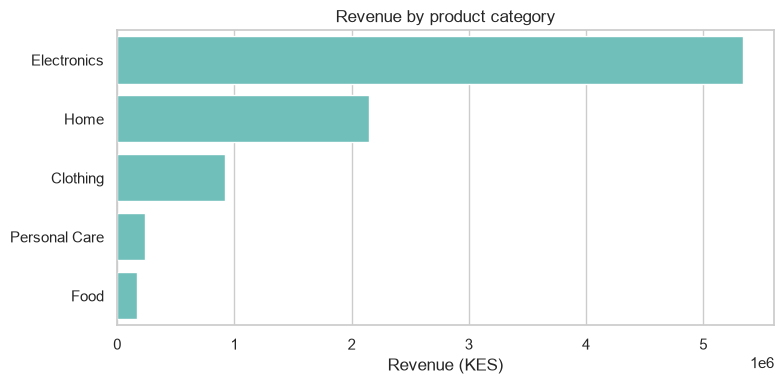

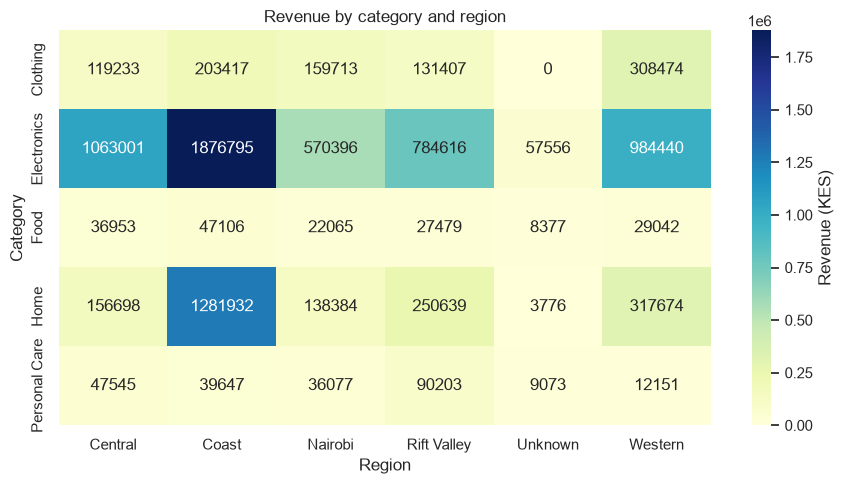

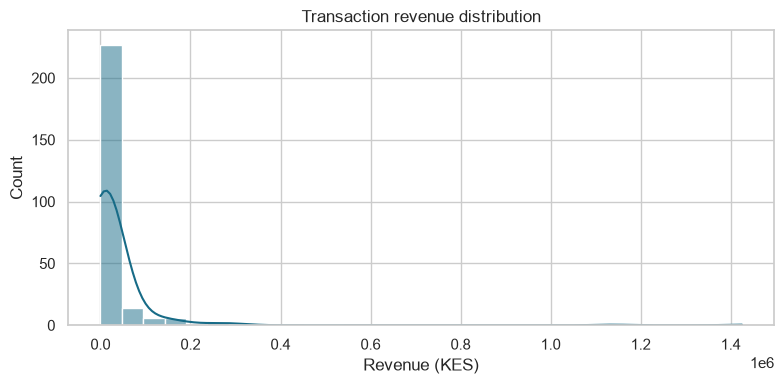

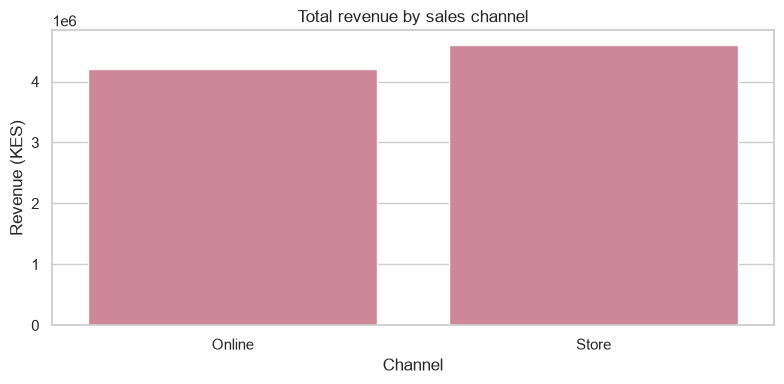

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
daily = retail.groupby(retail["Date"].dt.date)["Revenue_KES"].sum()
daily.plot(ax=ax, color="#176B87")
ax.set(title="Daily net sales revenue", xlabel="Date", ylabel="Revenue (KES)")
fig.tight_layout(); fig.savefig(FIG / "A2_01_daily_revenue.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=category, x="Revenue_KES", y="Product_Category",
            color="#64CCC5", ax=ax)
ax.set(title="Revenue by product category", xlabel="Revenue (KES)", ylabel="")
fig.tight_layout(); fig.savefig(FIG / "A2_02_category_revenue.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(category_region_revenue, annot=True, fmt=".0f", cmap="YlGnBu",
            cbar_kws={"label": "Revenue (KES)"}, ax=ax)
ax.set(title="Revenue by category and region", xlabel="Region", ylabel="Category")
fig.tight_layout(); fig.savefig(FIG / "A2_03_region_category.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(retail["Revenue_KES"], bins=30, kde=True, ax=ax, color="#176B87")
ax.set(title="Transaction revenue distribution", xlabel="Revenue (KES)")
fig.tight_layout(); fig.savefig(FIG / "A2_04_revenue_distribution.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=channel, x="Sales_Channel", y="Revenue_KES",
            color="#DA7B93", ax=ax)
ax.set(title="Total revenue by sales channel", xlabel="Channel", ylabel="Revenue (KES)")
fig.tight_layout(); fig.savefig(FIG / "A2_05_channel_revenue.png", dpi=160); plt.show()

## Regression model comparison
A fixed 80:20 random split is used for this introductory, transaction-level comparison, with 5-fold cross-validation restricted to training data. The held-out test set is evaluated once. One-hot encoding is fitted inside each pipeline. The linear and forest models use the same predictors and split.

**Important leakage/interpretation note:** units, unit price and discount directly determine the formula-derived target. This is a reconstruction exercise, not evidence that these models can predict demand or future sales. Cross-validation cannot fix that design limitation.

,Model,CV MAE (KES),CV RMSE (KES),Test MAE (KES),Test RMSE (KES),Test R-squared
0,Training mean baseline,NaN,NaN,53073.10,196345.35,-0.01
1,Linear regression,21602.18,37904.97,23151.35,35013.69,0.97
2,Random forest,12953.11,56356.95,32994.54,151522.89,0.40


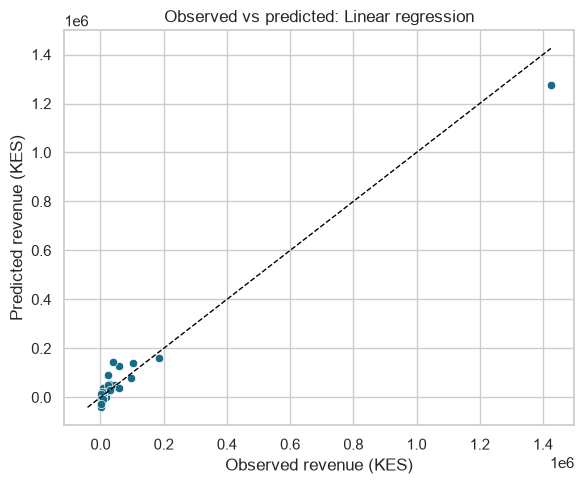

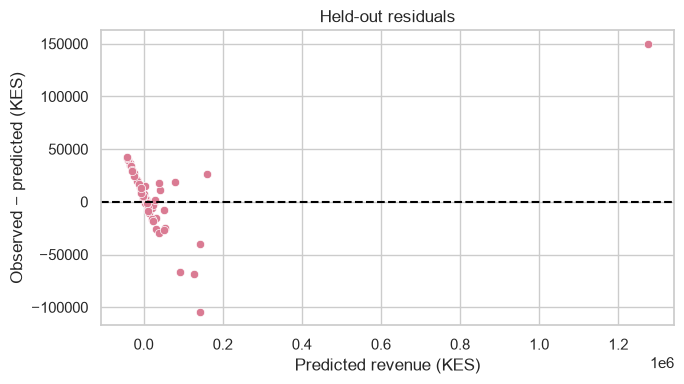

Chosen by held-out test MAE for comparison only: Linear regression


In [5]:
target = "Revenue_KES"
numeric_features = [
    "Units_Sold", "Unit_Price_KES", "Discount_Rate", "Month",
    "Day_Of_Week", "Is_Weekend",
]
categorical_features = [
    "Product_Category", "Region", "Payment_Method", "Sales_Channel",
]
features = numeric_features + categorical_features
X = retail[features]
y = retail[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])
models = {
    "Training mean baseline": DummyRegressor(strategy="mean"),
    "Linear regression": Pipeline([
        ("preprocess", preprocess), ("model", LinearRegression())
    ]),
    "Random forest": Pipeline([
        ("preprocess", preprocess),
        ("model", RandomForestRegressor(
            n_estimators=300, min_samples_leaf=2, random_state=SEED
        )),
    ]),
}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
fitted = {}
for name, model in models.items():
    if name != "Training mean baseline":
        cv_result = cross_validate(
            model, X_train, y_train, cv=cv,
            scoring={"mae": "neg_mean_absolute_error",
                     "rmse": "neg_root_mean_squared_error",
                     "r2": "r2"},
            return_train_score=False,
        )
        cv_mae = -cv_result["test_mae"].mean()
        cv_rmse = -cv_result["test_rmse"].mean()
    else:
        cv_mae = np.nan
        cv_rmse = np.nan
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted[name] = (model, pred)
    rows.append({
        "Model": name,
        "CV MAE (KES)": cv_mae,
        "CV RMSE (KES)": cv_rmse,
        "Test MAE (KES)": mean_absolute_error(y_test, pred),
        "Test RMSE (KES)": mean_squared_error(y_test, pred) ** 0.5,
        "Test R-squared": r2_score(y_test, pred),
    })
model_results = pd.DataFrame(rows)
display(model_results.round(2))
model_results.to_csv(OUT / "A2_Retail_model_comparison.csv", index=False)

best_name = model_results.loc[
    model_results["Test MAE (KES)"].idxmin(), "Model"
]
best_model, best_pred = fitted[best_name]
residuals = y_test.to_numpy() - best_pred
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(x=y_test, y=best_pred, ax=ax, color="#176B87")
limits = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
ax.plot(limits, limits, "--", color="black", linewidth=1)
ax.set(title=f"Observed vs predicted: {best_name}",
       xlabel="Observed revenue (KES)", ylabel="Predicted revenue (KES)")
fig.tight_layout(); fig.savefig(FIG / "A2_06_observed_predicted.png", dpi=160); plt.show()
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(x=best_pred, y=residuals, ax=ax, color="#DA7B93")
ax.axhline(0, color="black", linestyle="--")
ax.set(title="Held-out residuals", xlabel="Predicted revenue (KES)",
       ylabel="Observed − predicted (KES)")
fig.tight_layout(); fig.savefig(FIG / "A2_07_residuals.png", dpi=160); plt.show()
print("Chosen by held-out test MAE for comparison only:", best_name)

## Executive summary and recommendations
The summary below is generated from the cleaned sample and model results. Review it alongside the synthetic-data caveats before using it as a decision-support document.

In [6]:
total_rev = retail["Revenue_KES"].sum()
tx_count = retail["Transaction_ID"].nunique()
avg_tx = retail["Revenue_KES"].mean()
med_tx = retail["Revenue_KES"].median()
unit_total = retail["Units_Sold"].sum()
top_cat = category.iloc[0]
top_units = category.loc[category["Units_Sold"].idxmax()]
top_month = monthly.loc[monthly["Revenue_KES"].idxmax()]
low_month = monthly.loc[monthly["Revenue_KES"].idxmin()]
top_channel = channel.loc[channel["Revenue_KES"].idxmax()]
best_metrics = model_results.loc[model_results["Model"] == best_name].iloc[0]
retail_summary = f'''
# Executive summary — Retail Sales Analytics

**Scope.** This analysis examined {tx_count} unique transactions from {retail["Date"].min():%d %B %Y} to {retail["Date"].max():%d %B %Y}. The workbook states that records are simulated for teaching. They do not represent actual customers or retailer operations, so the results are an exercise in reproducible analysis rather than a basis for staffing, inventory, pricing or regional investment decisions. Revenue is reported in Kenyan shillings (KES). I removed exact repeated transaction IDs, kept unusual transactions, recorded missingness, used an explicit Unknown category for missing region/payment method and imputed missing unit prices using the median within product category. Net revenue was recalculated as units multiplied by unit price and one minus the discount rate; differences from the supplied revenue were retained in the audit fields.

**Overall performance in this sample.** The cleaned records sum to KES {total_rev:,.2f} across {unit_total:,} units. Mean transaction revenue is KES {avg_tx:,.2f}, while the median is KES {med_tx:,.2f}. The mean being higher than the median indicates that a smaller number of large transactions pull the average upward. The reported totals depend on the assignment’s revenue formula and the price imputation described above. An unusually high unit price was retained and flagged rather than removed: a high value might be a genuine transaction or a data-entry error and the workbook alone cannot resolve that question. A manager should verify such observations against original receipts before making decisions.

**Category and time findings.** {top_cat["Product_Category"]} generated the greatest total revenue, KES {top_cat["Revenue_KES"]:,.2f}, from {int(top_cat["Transactions"])} transactions. {top_units["Product_Category"]} had the largest number of units sold ({int(top_units["Units_Sold"]):,}). Revenue and unit rankings can differ because products have different prices and discount levels; unit volume is not the same as financial contribution. In the observed months, {top_month["Period"]} had the highest total revenue (KES {top_month["Revenue_KES"]:,.2f}) and {low_month["Period"]} the lowest (KES {low_month["Revenue_KES"]:,.2f}). These are descriptions of this short January–June 2025 sample, not evidence of a stable seasonal pattern. A full year or multiple years are needed to distinguish seasonality from random variation.

**Channel and customer-spend context.** {top_channel["Sales_Channel"]} had the largest aggregate revenue (KES {top_channel["Revenue_KES"]:,.2f}) among the listed channels. Aggregate revenue depends on both transaction count and average transaction value; it should not be interpreted as evidence that customers in one channel spend more until both measures and the group sizes are considered. Payment-method and regional differences may also reflect missing classifications, transaction mix, availability or sampling rather than underlying customer preferences. No causal conclusion is supported.

**Model results and their limits.** The {best_name} had held-out MAE KES {best_metrics["Test MAE (KES)"]:,.2f}, RMSE KES {best_metrics["Test RMSE (KES)"]:,.2f} and R-squared {best_metrics["Test R-squared"]:.3f}. MAE is the average absolute error; RMSE penalizes large errors more; R-squared describes variation explained relative to a mean prediction on this test split. Because units, price and discount directly determine the target, strong performance mainly demonstrates the arithmetic relationship and should not be presented as a demand forecast. The random split also does not test performance on a later period. A future forecasting study should define the forecast horizon, use a chronological split and use only information available at prediction time.

**Recommendations.** First, validate extreme prices and the revenue inconsistencies against source receipts, while preserving an audit trail; do not automatically discard high values. Second, collect a full year or more of verified transactions, stock availability, product identifiers and promotion context before evaluating inventory or sales strategies. A particularly useful additional field is **inventory availability at transaction time**, since recorded sales can be constrained by stockouts. Missing values, imputation, extreme observations, short coverage and synthetic records all reduce confidence. Limit access to transaction-level files, collect only fields needed for analysis and avoid using incomplete regional or payment comparisons to treat customers differently. Apply appropriate access controls, retention limits and privacy review to any real customer data.
'''
(OUT / "A2_Retail_Executive_Summary.md").write_text(
    retail_summary.strip() + "\n", encoding="utf-8"
)
print(retail_summary)
print("Executive summary word count:",
      len(retail_summary.split()))


# Executive summary — Retail Sales Analytics

**Scope.** This analysis examined 260 unique transactions from 01 January 2025 to 29 June 2025. The workbook states that records are simulated for teaching. They do not represent actual customers or retailer operations, so the results are an exercise in reproducible analysis rather than a basis for staffing, inventory, pricing or regional investment decisions. Revenue is reported in Kenyan shillings (KES). I removed exact repeated transaction IDs, kept unusual transactions, recorded missingness, used an explicit Unknown category for missing region/payment method and imputed missing unit prices using the median within product category. Net revenue was recalculated as units multiplied by unit price and one minus the discount rate; differences from the supplied revenue were retained in the audit fields.

**Overall performance in this sample.** The cleaned records sum to KES 8,813,868.92 across 1,296 units. Mean transaction revenue is KES 33,8

## Reproducibility note
- Workbook/sheet: `DSA1101_Practical_Assignments_Datasets.xlsx` / `A2_Retail_Sales`.
- Random seed: 42; test size: 20%; training cross-validation: shuffled 5-fold.
- Cleaning: deduplicate by transaction ID, preserve unknown categorical values, category-median price imputation, formula-derived revenue, retain and flag extremes.
- Models: training-mean baseline, linear regression and random forest (`n_estimators=300`, `min_samples_leaf=2`), with preprocessing inside pipelines.
- Rerun: place the workbook beside this notebook, install pandas, NumPy, Matplotlib, Seaborn, scikit-learn and openpyxl, then run all cells from a clean kernel.
- This notebook exports cleaned data, audit log, summary tables, model metrics, charts and the executive summary under `outputs/`.